In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

print("Insider Threat Detection project initialized.")
print("Libraries imported successfully.")


Insider Threat Detection project initialized.
Libraries imported successfully.


In [3]:

np.random.seed(42)

n = 3000

df = pd.DataFrame({
    "after_hours_logins": np.random.poisson(1, n),
    "file_downloads": np.random.poisson(5, n),
    "usb_usage": np.random.binomial(1, 0.15, n),
    "failed_logins": np.random.poisson(1, n),
    "external_emails": np.random.poisson(3, n),
    "sensitive_file_access": np.random.poisson(2, n),
    "weekend_activity": np.random.binomial(1, 0.12, n)
})

risk_score = (
    (df["after_hours_logins"] >= 3).astype(int)
    + (df["file_downloads"] >= 12).astype(int)
    + df["usb_usage"]
    + (df["failed_logins"] >= 4).astype(int)
    + (df["external_emails"] >= 8).astype(int)
    + (df["sensitive_file_access"] >= 6).astype(int)
    + df["weekend_activity"]
)

probability = 1 / (1 + np.exp(-(risk_score - 2.5)))
df["is_suspicious"] = np.random.binomial(
    1, np.clip(probability * 0.7 + 0.03, 0, 0.95)
)

print("Dataset created:", df.shape)
display(df.head())
print("\nClass distribution:")
display(df["is_suspicious"].value_counts())


Dataset created: (3000, 8)


,after_hours_logins,file_downloads,usb_usage,failed_logins,external_emails,sensitive_file_access,weekend_activity,is_suspicious
0,1,7,0,1,2,2,0,0
1,2,3,0,1,3,2,1,0
2,0,6,0,2,4,5,0,0
3,0,2,0,1,3,2,0,0
4,3,4,0,0,4,4,0,0



Class distribution:


,count
is_suspicious,
0,2664
1,336


In [4]:

# Separate input features and target label
X = df.drop(columns=["is_suspicious"])
y = df["is_suspicious"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Initialize the machine learning model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Model training completed!
Training records: 2400
Testing records: 600


In [5]:

# Generate predictions on test data
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Display evaluation metrics
print("CLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Normal", "Suspicious"],
        zero_division=0
    )
)

print("ROC-AUC Score:", round(roc_auc_score(y_test, y_prob), 4))


CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.89      0.95      0.92       533
  Suspicious       0.08      0.03      0.04        67

    accuracy                           0.85       600
   macro avg       0.48      0.49      0.48       600
weighted avg       0.80      0.85      0.82       600

ROC-AUC Score: 0.5245


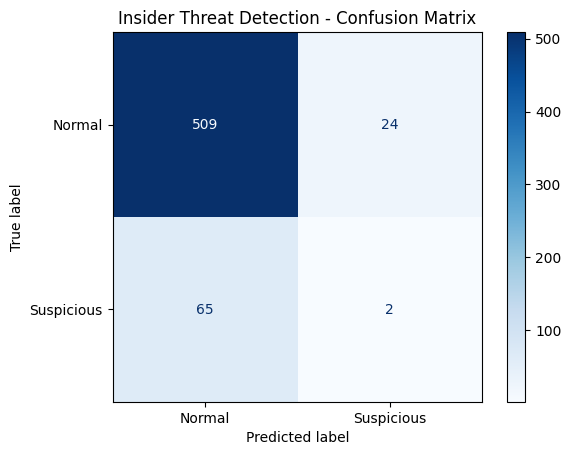

In [6]:

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Suspicious"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Insider Threat Detection - Confusion Matrix")
plt.show()


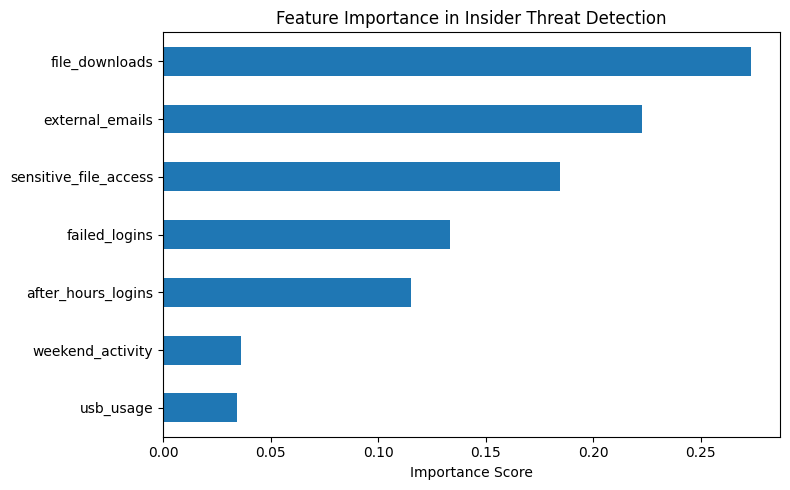

,Importance
file_downloads,0.273316
external_emails,0.222801
sensitive_file_access,0.184413
failed_logins,0.133632
after_hours_logins,0.115431
weekend_activity,0.036137
usb_usage,0.034270


In [7]:

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importance.plot(kind="barh")
plt.title("Feature Importance in Insider Threat Detection")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

display(importance.sort_values(ascending=False).to_frame("Importance"))


In [8]:

new_employee_activity = pd.DataFrame([{
    "after_hours_logins": 4,
    "file_downloads": 18,
    "usb_usage": 1,
    "failed_logins": 3,
    "external_emails": 10,
    "sensitive_file_access": 8,
    "weekend_activity": 1
}])

prediction = model.predict(new_employee_activity)[0]
risk_probability = model.predict_proba(new_employee_activity)[0, 1]

print("Prediction:", "Suspicious pattern - review" if prediction == 1
      else "No suspicious pattern flagged")
print(f"Model score: {risk_probability:.2%}")

display(new_employee_activity)


Prediction: No suspicious pattern flagged
Model score: 36.00%


,after_hours_logins,file_downloads,usb_usage,failed_logins,external_emails,sensitive_file_access,weekend_activity
0,4,18,1,3,10,8,1


In [9]:

import os
import json
import joblib

os.makedirs("insider_threat_outputs", exist_ok=True)

# Save the trained model
joblib.dump(
    model,
    "insider_threat_outputs/insider_threat_model.joblib"
)

# Save the synthetic dataset
df.to_csv(
    "insider_threat_outputs/synthetic_employee_activity.csv",
    index=False
)

# Save the evaluation results
metrics = {
    "dataset_type": "synthetic demonstration data",
    "test_accuracy": float((y_pred == y_test).mean()),
    "roc_auc": float(roc_auc_score(y_test, y_prob)),
    "note": "Not representative of real-world detection performance."
}

with open(
    "insider_threat_outputs/evaluation_metrics.json", "w"
) as file:
    json.dump(metrics, file, indent=4)

print("Project artifacts saved successfully.")

!ls -lh insider_threat_outputs


Project artifacts saved successfully.
total 7.5M
-rw-r--r-- 1 root root  201 Oct 27 16:22 evaluation_metrics.json
-rw-r--r-- 1 root root 7.5M Oct 27 16:22 insider_threat_model.joblib
-rw-r--r-- 1 root root  48K Oct 27 16:22 synthetic_employee_activity.csv


In [10]:
from google.colab import files
!zip -r insider_threat_outputs.zip insider_threat_outputs
files.download("insider_threat_outputs.zip")

  adding: insider_threat_outputs/ (stored 0%)
  adding: insider_threat_outputs/evaluation_metrics.json (deflated 27%)
  adding: insider_threat_outputs/synthetic_employee_activity.csv (deflated 79%)
  adding: insider_threat_outputs/insider_threat_model.joblib (deflated 80%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:

import os

print("Current directory:", os.getcwd())
print("Available files:", os.listdir("."))

Current directory: /content
Available files: ['.config', 'insider_threat_outputs', 'insider_threat_outputs.zip', 'sample_data']


In [13]:
!ls -lh insider_threat_outputs

total 7.5M
-rw-r--r-- 1 root root  201 Oct 27 16:22 evaluation_metrics.json
-rw-r--r-- 1 root root 7.5M Oct 27 16:22 insider_threat_model.joblib
-rw-r--r-- 1 root root  48K Oct 27 16:22 synthetic_employee_activity.csv


In [14]:
from google.colab import files
import shutil

shutil.make_archive(
    "insider_threat_outputs",
    "zip",
    "insider_threat_outputs"
)

files.download("insider_threat_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>